# Taller II. Preparación de datos para predicción del consumo energético (UPTC)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

## Carga de datos

In [2]:
ruta = 'consumos_uptc.csv'
if EN_COLAB:
    try:
        drive.mount('/content/drive')
        ruta = '/content/drive/MyDrive/consumos_uptc.csv'
    except Exception as e:
        print(f"Error al montar Google Drive: {e}")

df = pd.read_csv(ruta)
df.head()

,reading_id,timestamp,sede,sede_id,energia_total_kwh,energia_comedor_kwh,energia_salones_kwh,energia_laboratorios_kwh,energia_auditorios_kwh,energia_oficinas_kwh,potencia_total_kw,agua_litros,temperatura_exterior_c,ocupacion_pct,hora,dia_semana,dia_nombre,mes,trimestre,año,periodo_academico,es_fin_semana,es_festivo,es_semana_parciales,es_semana_finales,co2_kg
0,1,2018-01-01 00:00:00,Chiquinquirá,UPTC_CHI,0.928,0.0452,0.1497,0.4334,0.0386,0.2613,1.172,25.44,6.8,4.3,0,0,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.1877
1,2,2018-01-01 00:00:00,Duitama,UPTC_DUI,2.592,0.1129,0.2007,1.7993,0.0573,0.4217,3.513,107.57,10.9,4.1,0,0,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.4490
2,3,2018-01-01 00:00:00,Sogamoso,UPTC_SOG,2.841,0.1395,0.2388,1.9638,NaN,0.4443,4.336,80.13,9.2,5.7,0,0,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.6048
3,4,2018-01-01 00:00:00,Tunja,UPTC_TUN,1.505,0.0892,0.1091,0.9672,0.0364,0.3031,1.735,1307.49,5.3,4.6,0,0,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.2872
4,5,2018-01-01 01:00:00,Chiquinquirá,UPTC_CHI,0.917,0.0479,0.1432,0.4071,0.0418,0.2766,1.082,25.30,7.1,3.8,1,0,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.1599


**Análisis.** Son lecturas horarias de las 4 sedes entre enero de 2018 y octubre de 2025. Ya se ve un nulo en `energia_auditorios_kwh` (Sogamoso) y que `timestamp` viene como texto.

## Fase I. Exploración inicial

In [3]:
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")

Filas: 275387 | Columnas: 26


**Análisis.** El conjunto tiene 275.387 registros y 26 columnas.

In [4]:
df.dtypes.to_frame('tipo')

,tipo
reading_id,int64
timestamp,object
sede,object
sede_id,object
energia_total_kwh,float64
energia_comedor_kwh,float64
energia_salones_kwh,float64
energia_laboratorios_kwh,float64
energia_auditorios_kwh,float64
energia_oficinas_kwh,float64


**Análisis.** Hay 11 variables numéricas decimales, 6 enteras, 4 booleanas y 5 de texto. `timestamp` es texto, no fecha.

In [5]:
df.groupby('sede')['sede_id'].value_counts()

sede          sede_id 
Chiquinquirá  UPTC_CHI    68785
              UPTC-CHI       44
              uptc_chi       30
Duitama       UPTC_DUI    68808
              uptc_dui       31
              UPTC-DUI       23
Sogamoso      UPTC_SOG    68762
              uptc_sog       34
              UPTC-SOG       33
Tunja         UPTC_TUN    68768
              uptc_tun       37
              UPTC-TUN       32
Name: count, dtype: int64

**Análisis.** Las 4 sedes tienen cerca de 68.850 registros cada una (balanceado). Pero cada sede aparece con 3 formatos de `sede_id` (`UPTC_DUI`, `UPTC-DUI`, `uptc_dui`), una inconsistencia a corregir.

In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
reading_id,275387.0,137694.00,79497.52,1.00,68847.50,137694.00,206540.50,275387.00
energia_total_kwh,275387.0,5.08,6.12,-38.99,1.46,3.60,5.71,190.46
energia_comedor_kwh,267133.0,0.30,0.38,0.00,0.09,0.19,0.39,3.55
energia_salones_kwh,275387.0,0.98,1.62,0.01,0.16,0.32,0.69,9.53
energia_laboratorios_kwh,275387.0,2.43,2.19,0.12,0.80,1.69,3.41,39.68
energia_auditorios_kwh,261769.0,0.10,0.21,0.00,0.04,0.06,0.08,2.37
energia_oficinas_kwh,275387.0,1.19,1.41,0.04,0.34,0.66,1.37,7.82
potencia_total_kw,275387.0,6.70,6.94,0.24,2.00,4.72,8.01,44.98
agua_litros,264405.0,645.32,1389.79,1.95,44.28,138.69,499.76,62606.26
temperatura_exterior_c,259002.0,14.03,4.93,2.00,10.20,14.00,17.90,26.00


**Análisis.** Hay valores imposibles: `energia_total_kwh` mínimo -38,99 y `co2_kg` mínimo -8,51. También hay extremos muy lejos de la mediana (total máx. 190 vs mediana 3,6; agua máx. 62.606 vs mediana 139). Los conteos menores a 275.387 muestran nulos en comedor, auditorios, agua, temperatura, ocupación y CO2.

In [7]:
df['periodo_academico'].value_counts()

periodo_academico
semestre_1          115325
semestre_2           79522
vacaciones_mitad     51114
vacaciones_fin       26637
SEMESTRE_1             726
Semestre_1             710
semestre1              699
vacaciones             654
Name: count, dtype: int64

**Análisis.** Hay 8 etiquetas para 4 categorías reales: `semestre_1` aparece como `SEMESTRE_1`, `Semestre_1` y `semestre1`. Además `vacaciones` (654) no dice si es de mitad o fin de año.

In [8]:
sectores = ['energia_comedor_kwh', 'energia_salones_kwh', 'energia_laboratorios_kwh',
            'energia_auditorios_kwh', 'energia_oficinas_kwh']

completo = df.dropna(subset=sectores)
dif = (completo['energia_total_kwh'] - completo[sectores].sum(axis=1)).abs()
print(f"Registros con total distinto a la suma de sectores: {(dif > 0.01).sum()} de {len(completo)}")

Registros con total distinto a la suma de sectores: 3568 de 253921


**Análisis.** En 3.568 registros (1,4 %) el total no coincide con la suma de los 5 sectores, así que hay anomalías en `energia_total_kwh` además de los negativos.

## Fase II. Limpieza y preparación inicial

In [9]:
nulos = df.isna().sum()
nulos[nulos > 0]

energia_comedor_kwh        8254
energia_auditorios_kwh    13618
agua_litros               10982
temperatura_exterior_c    16385
ocupacion_pct             32766
co2_kg                    13796
dtype: int64

**Análisis.** `ocupacion_pct` es la variable con más nulos (32.766, ~12 %), seguida de temperatura (16.385), CO2 (13.796), auditorios (13.618), agua (10.982) y comedor (8.254). Las demás columnas están completas.

In [10]:
df_dui = df[df['sede'].str.upper() == 'DUITAMA'].copy()
print(f"Registros antes del filtro: {len(df)}")
print(f"Registros después del filtro: {len(df_dui)}")

Registros antes del filtro: 275387


Registros después del filtro: 68862


**Análisis.** Al filtrar Duitama quedan 68.862 de 275.387 registros (~25 %).

In [11]:
df_dui['sede_id'] = df_dui['sede_id'].str.upper().str.replace('-', '_')
df_dui['periodo_academico'] = (df_dui['periodo_academico'].str.lower()
                               .replace({'semestre1': 'semestre_1', 'vacaciones': np.nan}))
print(df_dui['sede_id'].value_counts())
print(df_dui['periodo_academico'].value_counts(dropna=False))

sede_id
UPTC_DUI    68862
Name: count, dtype: int64
periodo_academico
semestre_1          29349
semestre_2          19912
vacaciones_mitad    12772
vacaciones_fin       6670
NaN                   159
Name: count, dtype: int64


**Análisis.** `sede_id` queda en un único valor (`UPTC_DUI`) y `periodo_academico` en 4 categorías. Las 159 filas con `vacaciones` pasan a nulo porque no se puede saber su categoría; se imputan con la moda más adelante.

In [12]:
cols_neg = sectores + ['energia_total_kwh', 'agua_litros', 'co2_kg']
(df_dui[cols_neg] < 0).sum()

energia_comedor_kwh           0
energia_salones_kwh           0
energia_laboratorios_kwh      0
energia_auditorios_kwh        0
energia_oficinas_kwh          0
energia_total_kwh           155
agua_litros                   0
co2_kg                      143
dtype: int64

**Análisis.** Los sectores y el agua no tienen negativos. Aparecen 155 en `energia_total_kwh` (columna que se agregó a la revisión) y 143 en `co2_kg`.

In [13]:
antes = len(df_dui)
df_dui = df_dui[~(df_dui[cols_neg] < 0).any(axis=1)]
print(f"Antes: {antes} | Después: {len(df_dui)} | Eliminados: {antes - len(df_dui)}")

Antes: 68862 | Después: 68707 | Eliminados: 155


**Análisis.** Se eliminan 155 registros. Los 143 negativos de CO2 estaban dentro de esos mismos registros, por eso el total eliminado coincide con los negativos de energía total.

In [14]:
completo = df_dui.dropna(subset=sectores)
dif = (completo['energia_total_kwh'] - completo[sectores].sum(axis=1)).abs()
malos = dif[dif > 0.01].index
df_dui.loc[malos, 'energia_total_kwh'] = completo.loc[malos, sectores].sum(axis=1)
print(f"Totales corregidos con la suma de sectores: {len(malos)}")

Totales corregidos con la suma de sectores: 741


**Análisis.** En 741 registros el total no cuadraba con la suma de sectores: 197 estaban en 0, 295 inflados (siempre unas 7,1 veces la suma, lo que apunta a un error sistemático de registro) y 249 por debajo de la suma. Se corrigen reemplazándolo por esa suma, que sí es consistente.

In [15]:
print(f"Duplicados exactos: {df_dui.duplicated().sum()}")
print(f"Duplicados por timestamp: {df_dui.duplicated('timestamp').sum()}")

Duplicados exactos: 0


Duplicados por timestamp: 220


**Análisis.** No hay duplicados exactos porque cada fila trae un `reading_id` distinto. Pero 220 lecturas repiten la misma hora (`timestamp`) de Duitama, lo que es un duplicado real.

In [16]:
antes = len(df_dui)
df_dui = df_dui.drop_duplicates('timestamp', keep='first')
print(f"Antes: {antes} | Después: {len(df_dui)}")

Antes: 68707 | Después: 68487


**Análisis.** Se eliminan 220 registros duplicados y quedan 68.487 lecturas, una por hora.

## Fase III. Análisis exploratorio de datos (EDA)

In [17]:
df_dui[sectores].describe().round(3)

,energia_comedor_kwh,energia_salones_kwh,energia_laboratorios_kwh,energia_auditorios_kwh,energia_oficinas_kwh
count,66408.000,68487.000,68487.000,65126.000,68487.000
mean,0.412,1.371,3.585,0.131,1.606
std,0.461,2.100,2.246,0.277,1.718
min,0.014,0.044,0.614,0.011,0.148
25%,0.143,0.315,2.157,0.055,0.630
50%,0.351,0.414,3.143,0.088,0.834
75%,0.475,1.025,4.268,0.108,1.895
max,3.552,9.535,38.995,2.371,7.822


**Análisis.** Laboratorios es el mayor consumidor (media 3,585 kWh, ~50 % de la suma de medias), seguido por oficinas (1,606) y salones (1,371). En todos los sectores la media supera la mediana, lo que indica distribuciones con cola a la derecha. Laboratorios llega a 38,99 kWh cuando su percentil 75 es 4,27, un valor extremo.

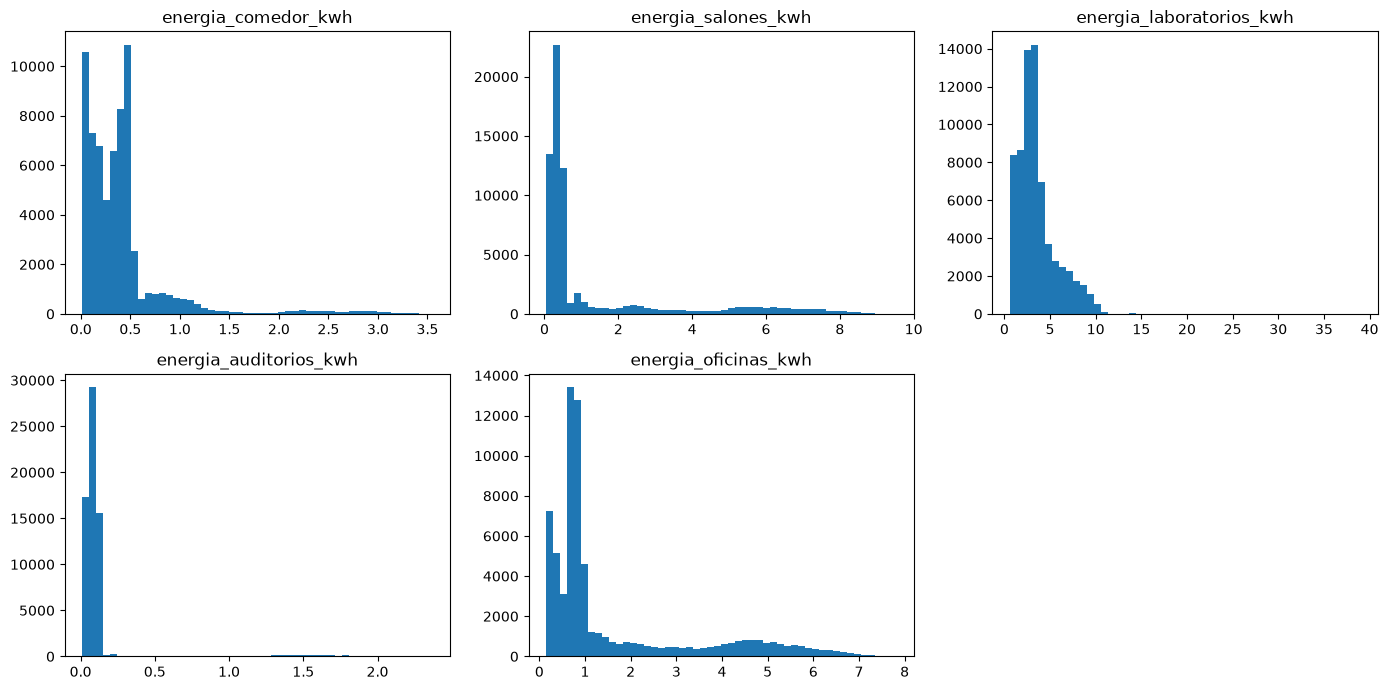

In [18]:
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
ejes = ejes.flatten()
for eje, col in zip(ejes, sectores):
    eje.hist(df_dui[col].dropna(), bins=50)
    eje.set_title(col)
ejes[-1].axis('off')
plt.tight_layout()
plt.show()

**Análisis.** Laboratorios se concentra entre 1 y 5 kWh y tiene unos pocos valores aislados hasta ~39. Salones y oficinas tienen dos grupos: uno de consumo bajo (cerca de 0 a 1 kWh) y otro de consumo alto (salones 4 a 8 kWh, oficinas 4 a 6 kWh), lo que sugiere horas y periodos de uso diferentes. Comedor y auditorios son casi siempre bajos, con un grupo pequeño de picos (comedor 2 a 3,5 kWh y auditorios 1,3 a 2,3 kWh).

In [19]:
nulos = df_dui.isna().sum()
nulos[nulos > 0]

energia_comedor_kwh       2079
energia_auditorios_kwh    3361
agua_litros               2753
temperatura_exterior_c    4131
ocupacion_pct             8307
periodo_academico          158
co2_kg                    3357
dtype: int64

**Análisis.** Tras la limpieza quedan nulos en ocupación (8.307), temperatura (4.131), auditorios (3.361), CO2 (3.357), agua (2.753), comedor (2.079) y `periodo_academico` (158).

In [20]:
num = df_dui.select_dtypes(include='number').columns
cat = df_dui.select_dtypes(exclude=['number', 'bool']).columns

df_dui[num] = df_dui[num].fillna(df_dui[num].median())
for col in cat:
    df_dui[col] = df_dui[col].fillna(df_dui[col].mode()[0])

print(f"Nulos restantes: {df_dui.isna().sum().sum()}")

Nulos restantes: 0


**Análisis.** Se imputa con mediana (numéricas) y moda (categóricas) y no queda ningún nulo. La mediana no distorsiona los extremos, pero reduce algo la variabilidad, sobre todo en ocupación, que tenía más nulos.

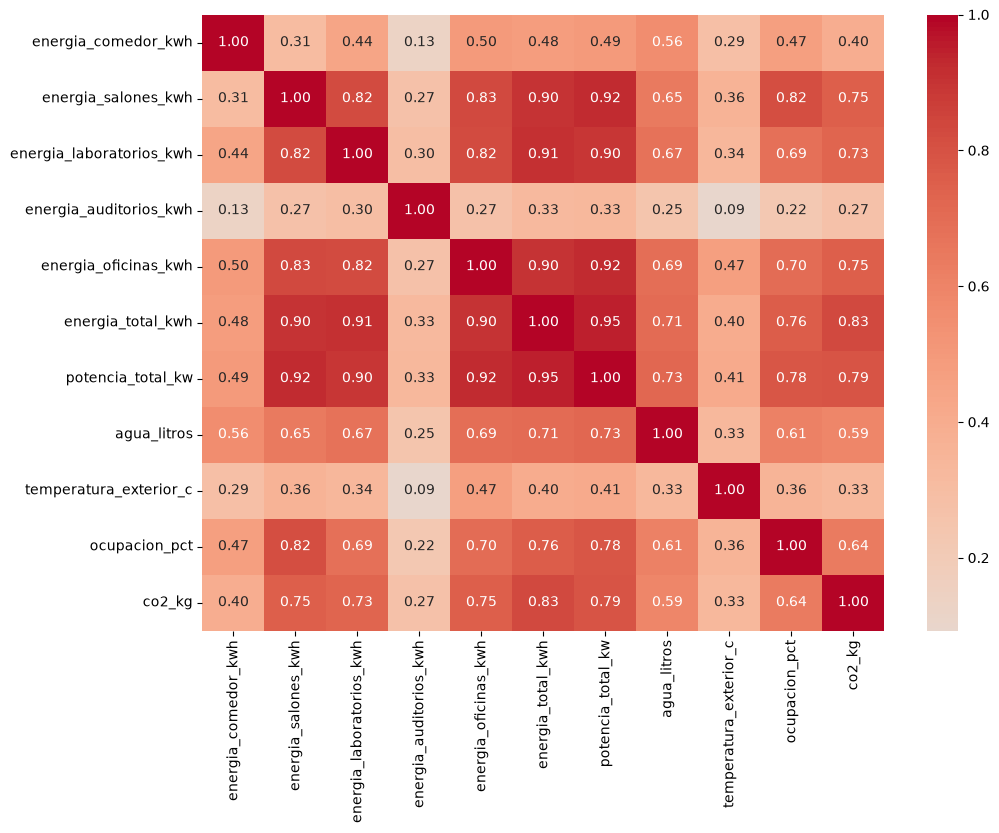

In [21]:
cols_corr = sectores + ['energia_total_kwh', 'potencia_total_kw', 'agua_litros',
                        'temperatura_exterior_c', 'ocupacion_pct', 'co2_kg']

plt.figure(figsize=(11, 8))
sns.heatmap(df_dui[cols_corr].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

**Análisis.** `energia_total_kwh` se relaciona muy fuerte con salones (0,90), laboratorios (0,91), oficinas (0,90) y potencia (0,95), y bastante con ocupación (0,76), CO2 (0,83) y agua (0,71). Con temperatura es débil (0,40) y con auditorios bajo (0,33). Salones, laboratorios y oficinas están correlacionados entre sí (0,82 a 0,83), es decir, suben y bajan juntos. Salones y ocupación llegan a 0,82.

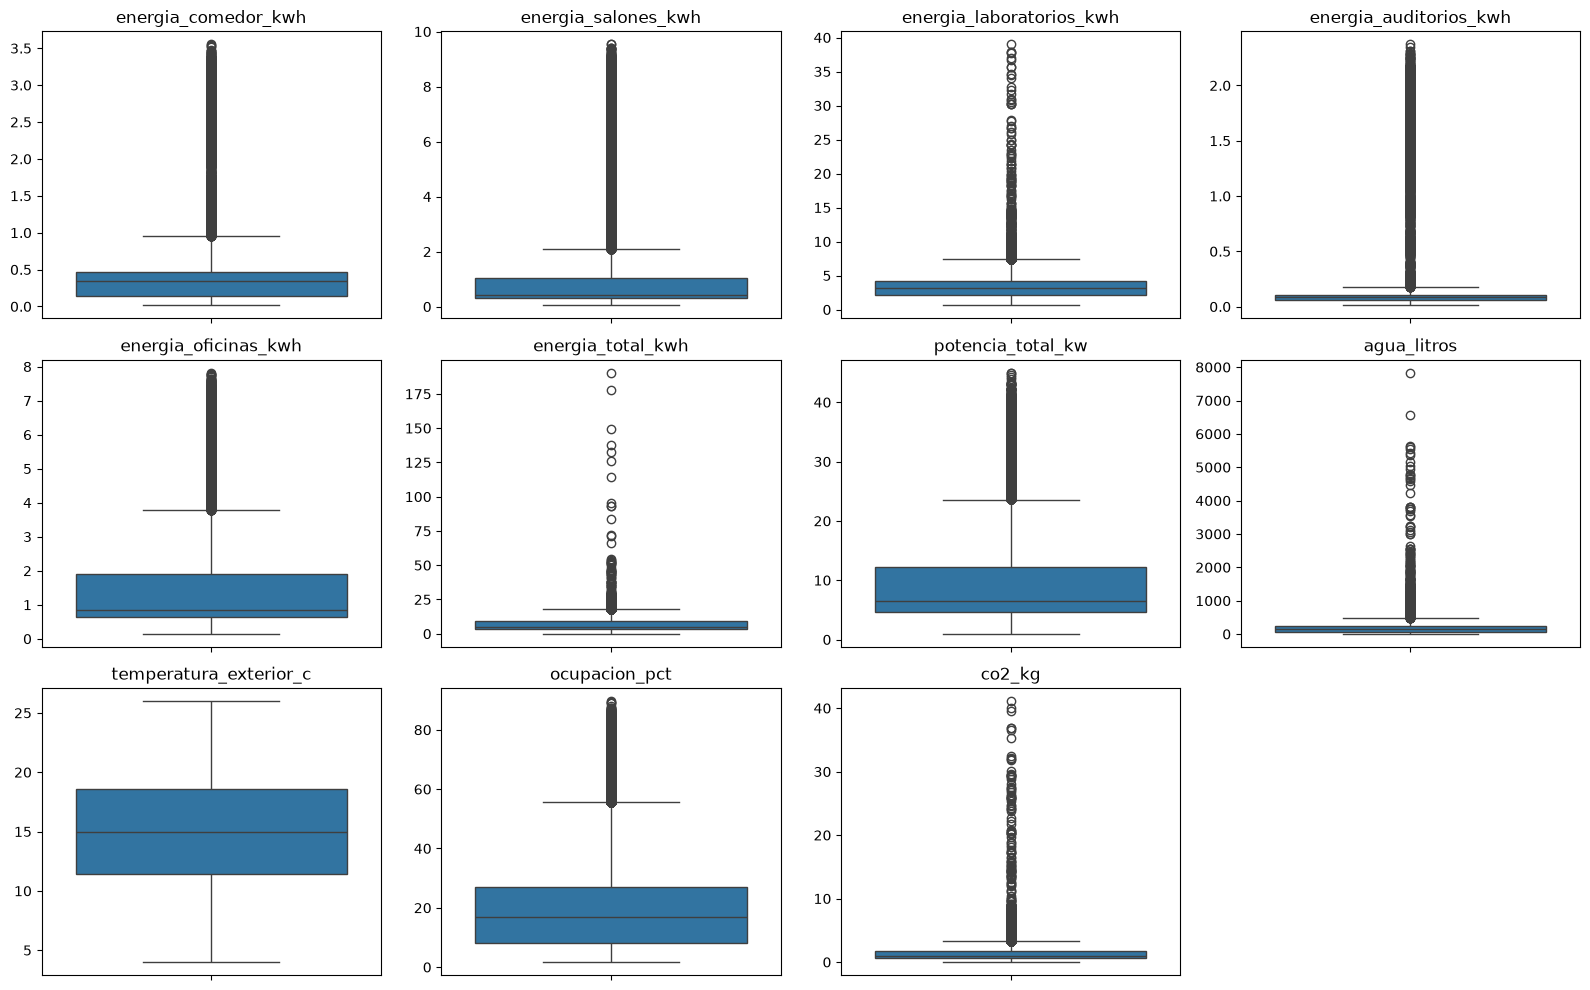

In [22]:
cols_num = sectores + ['energia_total_kwh', 'potencia_total_kw', 'agua_litros',
                       'temperatura_exterior_c', 'ocupacion_pct', 'co2_kg']

fig, ejes = plt.subplots(3, 4, figsize=(16, 10))
ejes = ejes.flatten()
for eje, col in zip(ejes, cols_num):
    sns.boxplot(y=df_dui[col], ax=eje)
    eje.set_title(col)
    eje.set_ylabel('')
ejes[-1].axis('off')
plt.tight_layout()
plt.show()

**Análisis.** Casi todas las variables tienen muchos puntos sobre el bigote superior y ninguno por debajo, es decir, los atípicos son valores altos. En comedor, salones, oficinas, auditorios, potencia y ocupación forman una columna continua de puntos, lo que apunta a picos de uso frecuentes y no a errores aislados. Los casos extremos y aislados están en `energia_total_kwh` (hasta 190 kWh, cuando el bigote termina cerca de 18), `agua_litros` (hasta ~7.800 litros, con bigote cerca de 500), `co2_kg` y `energia_laboratorios_kwh` (hasta 39 kWh). `temperatura_exterior_c` no tiene atípicos.

In [23]:
q1 = df_dui[cols_num].quantile(0.25)
q3 = df_dui[cols_num].quantile(0.75)
iqr = q3 - q1
atipicos = ((df_dui[cols_num] < q1 - 1.5 * iqr) | (df_dui[cols_num] > q3 + 1.5 * iqr)).sum()

tabla = pd.DataFrame({'atipicos': atipicos,
                      'porcentaje': (atipicos / df_dui[cols_num].count() * 100).round(1),
                      'maximo': df_dui[cols_num].max().round(2),
                      'limite_superior': (q3 + 1.5 * iqr).round(2)})
tabla

,atipicos,porcentaje,maximo,limite_superior
energia_comedor_kwh,4748,6.9,3.55,0.96
energia_salones_kwh,14021,20.5,9.53,2.09
energia_laboratorios_kwh,5313,7.8,39.00,7.43
energia_auditorios_kwh,2951,4.3,2.37,0.18
energia_oficinas_kwh,11134,16.3,7.82,3.79
energia_total_kwh,6553,9.6,190.46,17.82
potencia_total_kw,6512,9.5,44.98,23.60
agua_litros,7726,11.3,7833.02,495.36
temperatura_exterior_c,0,0.0,26.00,29.40
ocupacion_pct,7967,11.6,89.70,55.50


**Análisis.** Los mayores porcentajes de atípicos están en salones (20,5 %) y oficinas (16,3 %), por su patrón de dos niveles (uso bajo y uso alto). Total, potencia, agua y CO2 rondan el 10 %. Temperatura no tiene atípicos. Ocupación marca 11,6 %, pero antes de imputar era 3,5 %: los 8.307 nulos reemplazados por la mediana (16,8) estrechan el rango intercuartílico y bajan el límite superior de 71,5 a 55,5, así que la mayoría de esos atípicos son un efecto de la imputación y no picos reales. Los valores más altos del total (190, 178, 149 kWh...) corresponden a filas con un sector nulo, por lo que no se pudieron verificar contra la suma de sectores; conviene revisarlos o limitarlos antes de modelar.

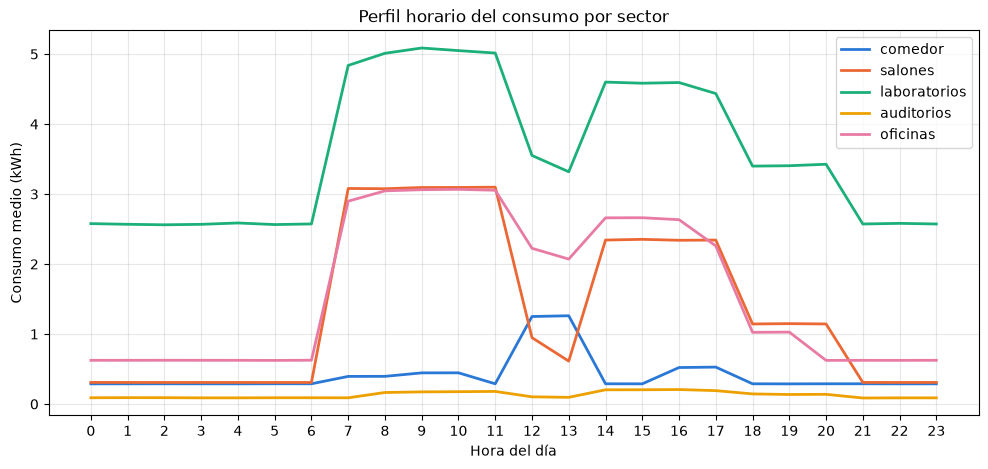

In [24]:
colores = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
perfil_hora = df_dui.groupby('hora')[sectores].mean()

fig, eje = plt.subplots(figsize=(12, 5))
for col, color in zip(sectores, colores):
    eje.plot(perfil_hora.index, perfil_hora[col], color=color, linewidth=2,
             label=col.replace('energia_', '').replace('_kwh', ''))
eje.set_xticks(range(24))
eje.set_xlabel('Hora del día')
eje.set_ylabel('Consumo medio (kWh)')
eje.set_title('Perfil horario del consumo por sector')
eje.grid(alpha=0.3)
eje.legend()
plt.show()

**Análisis.** El consumo sigue el horario académico. Entre las 7 y las 11 salones y oficinas pasan de menos de 0,7 kWh a cerca de 3 kWh, y en la tarde (14 a 17) se mantienen entre 2,3 y 2,7 kWh. Laboratorios sube de 2,6 a unos 5 kWh en las mismas franjas. A las 12 y 13 baja el consumo de salones y oficinas mientras el comedor alcanza su pico (1,3 kWh). Entre las 18 y las 20 salones sigue cerca de 1,1 kWh por la jornada nocturna. En la madrugada laboratorios conserva una carga base de 2,6 kWh, la mitad de su consumo en horas pico, lo que señala equipos encendidos todo el día y una oportunidad clara de ahorro.

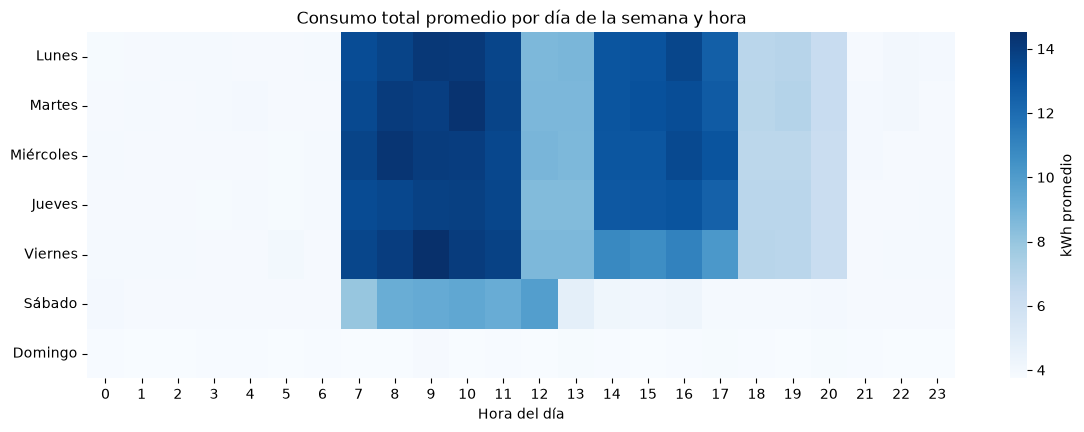

In [25]:
nombres_dia = df_dui.groupby('dia_semana')['dia_nombre'].first()
mapa = df_dui.pivot_table(index='dia_semana', columns='hora',
                          values='energia_total_kwh', aggfunc='mean')
mapa.index = nombres_dia.loc[mapa.index]

plt.figure(figsize=(14, 4.5))
sns.heatmap(mapa, cmap='Blues', cbar_kws={'label': 'kWh promedio'})
plt.title('Consumo total promedio por día de la semana y hora')
plt.xlabel('Hora del día')
plt.ylabel('')
plt.show()

**Análisis.** De lunes a viernes, entre las 7 y las 17, el consumo total promedio está entre 12,5 y 14,5 kWh, con una pausa a las 12 y 13 (cerca de 8,6 kWh); la excepción es el viernes en la tarde, que baja a 10 a 11 kWh. Entre las 18 y las 20 queda en 6 a 7 kWh. El sábado solo hay actividad de 7 a 12 (8 a 10 kWh) y el domingo se mantiene todo el día en la carga base de unos 3,8 kWh, igual que las noches. Esto confirma que `hora`, `dia_semana` y `es_fin_semana` son buenas variables predictoras.

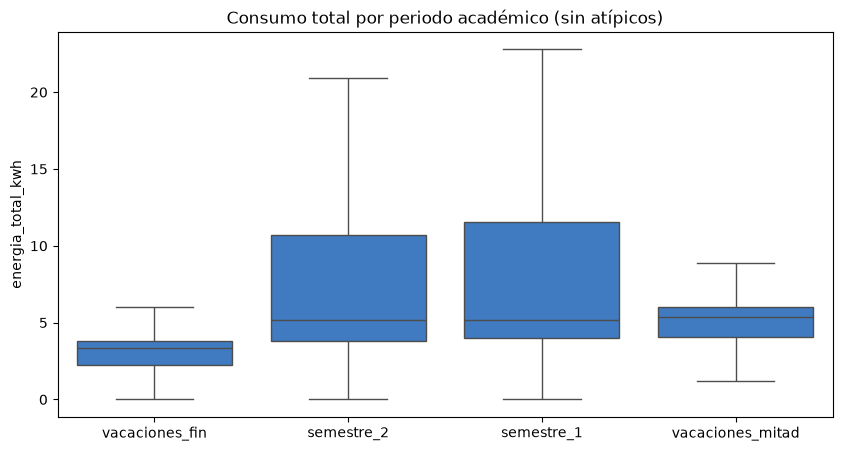

,count,mean,median
periodo_academico,,,
semestre_1,29347,8.16,5.16
semestre_2,19793,7.87,5.15
vacaciones_fin,6644,3.08,3.33
vacaciones_mitad,12703,5.70,5.34


In [26]:
orden = df_dui.groupby('periodo_academico')['energia_total_kwh'].median().sort_values().index

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_dui, x='periodo_academico', y='energia_total_kwh',
            order=orden, color='#2a78d6', showfliers=False)
plt.title('Consumo total por periodo académico (sin atípicos)')
plt.xlabel('')
plt.ylabel('energia_total_kwh')
plt.show()

df_dui.groupby('periodo_academico')['energia_total_kwh'].agg(['count', 'mean', 'median']).round(2)

**Análisis.** La mediana es parecida en los semestres y en vacaciones de mitad de año (5,2 a 5,3 kWh), pero los semestres tienen una caja mucho más ancha (tercer cuartil cerca de 11 kWh) y medias de 8,2 y 7,9 kWh por las horas de clase. Vacaciones de mitad de año se queda entre 4 y 6 kWh (media 5,7) y vacaciones de fin de año es el periodo más bajo (mediana 3,3 y media 3,1). Por eso `periodo_academico` aporta información al modelo, sobre todo en combinación con la hora.

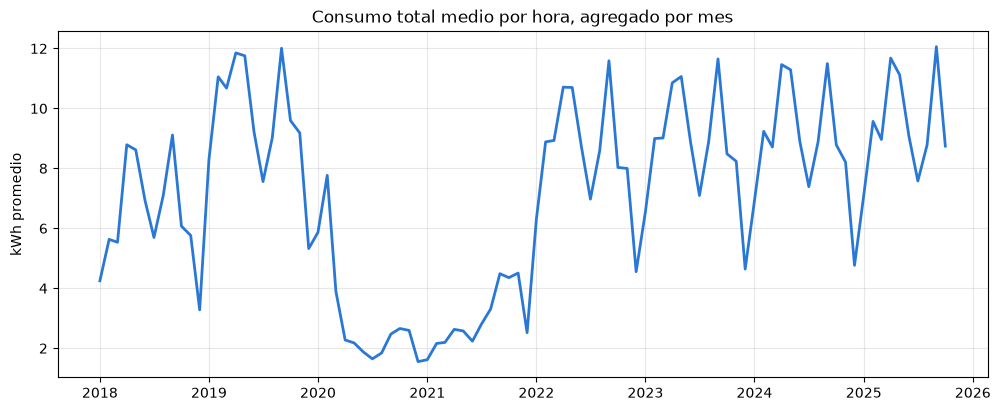

In [27]:
fechas = pd.to_datetime(df_dui['timestamp'])
serie_mes = df_dui.groupby(fechas.dt.to_period('M'))['energia_total_kwh'].mean()
serie_mes.index = serie_mes.index.to_timestamp()

fig, eje = plt.subplots(figsize=(12, 4.5))
eje.plot(serie_mes.index, serie_mes.values, color='#2a78d6', linewidth=2)
eje.set_title('Consumo total medio por hora, agregado por mes')
eje.set_ylabel('kWh promedio')
eje.grid(alpha=0.3)
plt.show()

**Análisis.** Desde abril de 2020 hasta agosto de 2021 el consumo medio cae por debajo de 3,4 kWh (mínimo 1,55 en diciembre de 2020), lo que coincide con la virtualidad por la pandemia. Desde septiembre de 2021 se recupera y en 2022 vuelve a los niveles previos. Cada año se repite el mismo ciclo: picos en abril, mayo y septiembre (cerca de 11 a 12 kWh) y caídas en julio y diciembre. El periodo 2020 a 2021 no representa la operación normal, así que conviene tenerlo en cuenta al separar datos de entrenamiento y prueba.

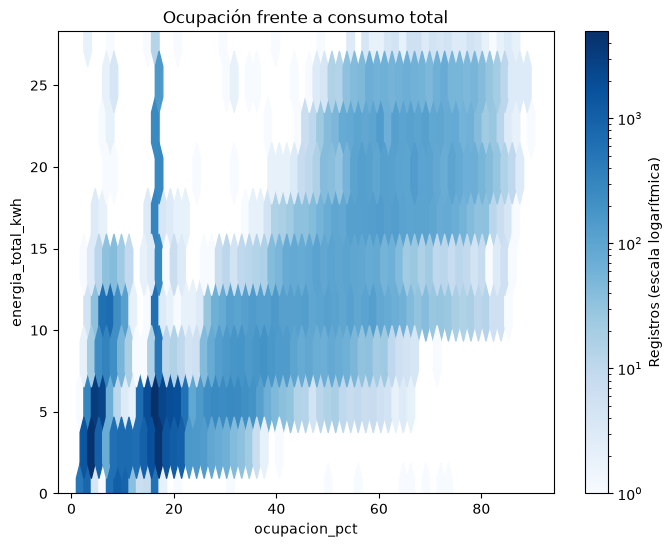

In [28]:
plt.figure(figsize=(8, 6))
plt.hexbin(df_dui['ocupacion_pct'], df_dui['energia_total_kwh'], gridsize=60,
           cmap='Blues', mincnt=1, bins='log')
plt.colorbar(label='Registros (escala logarítmica)')
plt.title('Ocupación frente a consumo total')
plt.xlabel('ocupacion_pct')
plt.ylabel('energia_total_kwh')
plt.ylim(0, df_dui['energia_total_kwh'].quantile(0.999))
plt.show()

**Análisis.** La relación es positiva y fuerte (correlación 0,76). Con ocupación hasta 30 % la mediana del consumo está entre 3,8 y 4,5 kWh; entre 30 y 40 % sube a 8,2 kWh, entre 40 y 60 % a 13,4 kWh y por encima de 60 % a 19,3 kWh. La franja vertical en 16,8 % son los 8.307 valores imputados con la mediana, que quedan repartidos en todo el rango de consumo; es el costo de la imputación y debilita un poco la relación con el objetivo.

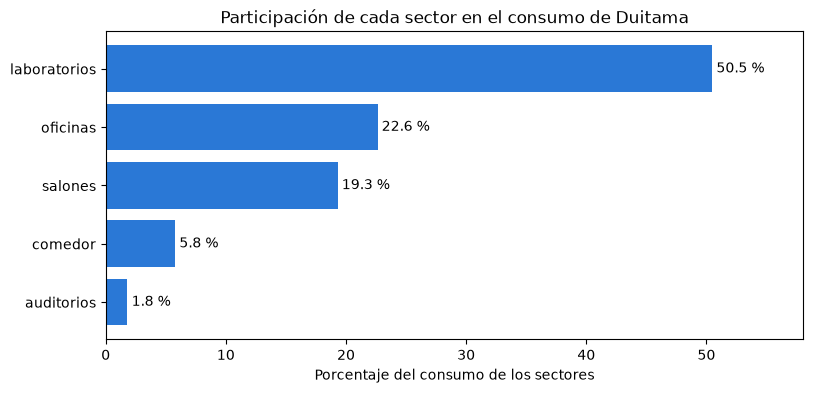

In [29]:
participacion = (df_dui[sectores].sum() / df_dui[sectores].sum().sum() * 100).sort_values()

fig, eje = plt.subplots(figsize=(9, 4))
barras = eje.barh(participacion.index.str.replace('energia_', '').str.replace('_kwh', ''),
                  participacion.values, color='#2a78d6')
eje.bar_label(barras, fmt='%.1f %%', padding=3)
eje.set_xlabel('Porcentaje del consumo de los sectores')
eje.set_title('Participación de cada sector en el consumo de Duitama')
eje.set_xlim(0, participacion.max() * 1.15)
plt.show()

**Análisis.** Laboratorios concentra la mitad del consumo de los sectores (50,5 %), seguido por oficinas (22,6 %) y salones (19,3 %). Comedor (5,8 %) y auditorios (1,8 %) pesan poco. Las acciones de ahorro tendrían más efecto en laboratorios, en especial sobre su carga base nocturna.

## Fase IV. Preparación para modelado

In [30]:
objetivos = ['energia_total_kwh', 'co2_kg']
features = ['ocupacion_pct', 'temperatura_exterior_c', 'hora', 'dia_semana', 'mes', 'trimestre',
            'año', 'es_fin_semana', 'es_festivo', 'es_semana_parciales', 'es_semana_finales',
            'periodo_academico']
excluidas = [c for c in df_dui.columns if c not in objetivos + features]

print(f"Objetivos: {objetivos}")
print(f"Features ({len(features)}): {features}")
print(f"Excluidas ({len(excluidas)}): {excluidas}")

Objetivos: ['energia_total_kwh', 'co2_kg']
Features (12): ['ocupacion_pct', 'temperatura_exterior_c', 'hora', 'dia_semana', 'mes', 'trimestre', 'año', 'es_fin_semana', 'es_festivo', 'es_semana_parciales', 'es_semana_finales', 'periodo_academico']
Excluidas (12): ['reading_id', 'timestamp', 'sede', 'sede_id', 'energia_comedor_kwh', 'energia_salones_kwh', 'energia_laboratorios_kwh', 'energia_auditorios_kwh', 'energia_oficinas_kwh', 'potencia_total_kw', 'agua_litros', 'dia_nombre']


**Análisis.** Se eligen como objetivos `energia_total_kwh` y `co2_kg`. Como features se usan la ocupación, la temperatura y las variables de calendario. Se excluyen los identificadores (la información de `timestamp` ya está en hora, día, mes y año), `sede` (constante), `dia_nombre` (repite `dia_semana`) y las variables de sectores, potencia y agua, porque se miden al mismo tiempo que el objetivo y darían fuga de información.

In [31]:
X = pd.get_dummies(df_dui[features], columns=['periodo_academico'], drop_first=True)
y = df_dui[objetivos]
df_final = pd.concat([X, y], axis=1)

print(f"Dimensiones finales: {df_final.shape}")
print(f"Nulos: {df_final.isna().sum().sum()} | Duplicados: {df_final.duplicated().sum()}")
df_final.head()

Dimensiones finales: (68487, 16)
Nulos: 0 | Duplicados: 0


,ocupacion_pct,temperatura_exterior_c,hora,dia_semana,mes,trimestre,año,es_fin_semana,es_festivo,es_semana_parciales,es_semana_finales,periodo_academico_semestre_2,periodo_academico_vacaciones_fin,periodo_academico_vacaciones_mitad,energia_total_kwh,co2_kg
1,4.1,10.9,0,0,1,1,2018,False,True,False,False,False,True,False,2.592,0.4490
5,4.5,9.9,1,0,1,1,2018,False,True,False,False,False,True,False,2.525,0.5529
9,4.1,8.0,2,0,1,1,2018,False,True,False,False,False,True,False,2.685,0.4908
13,5.6,9.8,3,0,1,1,2018,False,True,False,False,False,True,False,2.456,0.4837
17,4.7,10.5,4,0,1,1,2018,False,True,False,False,False,True,False,2.551,0.5567


**Análisis.** El conjunto final tiene 68.487 filas y 16 columnas: 14 predictoras (`periodo_academico` se convierte en 3 variables dummy) y 2 objetivos, sin nulos ni duplicados.

In [32]:
df_final.to_csv('consumos_uptc_duitama_modelado.csv', index=False)

## Conclusión

El conjunto de Duitama pasó de 68.862 a 68.487 registros tras eliminar 155 lecturas con negativos y 220 horas duplicadas; además se corrigieron 741 totales inconsistentes y se imputaron los nulos. El EDA muestra que el consumo depende sobre todo del horario académico, la ocupación y el periodo del año, y que laboratorios concentra la mitad de la energía con una carga base nocturna alta. El conjunto final (68.487 filas, 14 predictoras y 2 objetivos) queda listo para entrenar modelos, con dos cuidados: los totales extremos que no se pudieron verificar y el periodo 2020 a 2021, que no representa la operación normal.

## Exportación a HTML

Guardar el notebook antes de ejecutar la celda. El archivo HTML queda en la misma carpeta del notebook.

In [33]:
import subprocess
import sys

ruta_nb = ('/content/drive/MyDrive/Colab Notebooks/Taller_2_Consumo_Energetico_UPTC.ipynb'
           if EN_COLAB else 'Taller_2_Consumo_Energetico_UPTC.ipynb')
salida = subprocess.run([sys.executable, '-m', 'nbconvert', '--to', 'html',
                         '--HTMLExporter.exclude_anchor_links=True', ruta_nb],
                        capture_output=True, text=True)
print(salida.stderr)

[NbConvertApp] Converting notebook Taller_2_Consumo_Energetico_UPTC.ipynb to html
[NbConvertApp] Writing 374090 bytes to Taller_2_Consumo_Energetico_UPTC.html

